In [1]:
import pandas as pd
import seaborn as sns
import umap.umap_ as umap
import os


In [2]:
import sys  
sys.path.insert(0, '/home/m.caros/work/3DSemanticSegmentation/src/')
from models.pointnet import *
from bt.utils_barlow import *
from datasets import BarlowTwinsDataset
from torch.utils.data import DataLoader
from models.barlow_twins import *


In [3]:
sys.path.insert(0, '/home/m.caros/work/3DSemanticSegmentation/utils')
from utils_plot import plot_3d_coords

In [4]:
BATCH_SIZE = 1
z_dim=128
use_device = 'cuda'
NUM_CLASSES=6

## Data

In [5]:
dataset_folder = '/dades/LIDAR/towers_detection/datasets/pc_40x40_4096p_v3'
n_points = 4096
c_sample = False

In [6]:
path_list_files='/home/m.caros/work/3DSemanticSegmentation/train_test_files/RGBN_40x40_barlow_10'

# Datasets train / val / test
with open(os.path.join(path_list_files, 'train_cls_files.txt'), 'r') as f:
    train_files = f.read().splitlines()
with open(os.path.join(path_list_files, 'train_labeled_cls_files.txt'), 'r') as f:
    val_files = f.read().splitlines()
with open(os.path.join(path_list_files, 'test_cls_files.txt'), 'r') as f:
    test_files = f.read().splitlines()

# paths_files = glob.glob('/dades/LIDAR/towers_detection/datasets/pc_40x40_4096p/pylon*')
# towers_files = [f.split('/')[-1] for f in paths_files]

In [7]:
# Initialize datasets
test_dataset = BarlowTwinsDataset(dataset_folder=dataset_folder,
                           task='classification', 
                           number_of_points=n_points,
                           files=test_files,
                           fixed_num_points=False,
                           use_ground=False)

In [8]:

test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, 
                        num_workers=0, drop_last=False)



## Barlow Twins classifier

### Encoder: PointNet classifier

In [9]:
# classifier = ClassificationPointNet(num_classes=2,
#                                    point_dimension=3,
#                                    dataset=test_dataset,
#                                    device=use_device)

segmen_net = SegmentationPointNet(num_classes=NUM_CLASSES,
                                  point_dimension=3,
                                  device=use_device,
                                  is_barlow=True)

segmen_net = segmen_net.to(use_device)

pointnet_encoder = segmen_net.base_pointnet


### Init Barlow Twins model

In [10]:
encoder_out_dim=1024

ckpt_model = BarlowTwins(
    encoder=pointnet_encoder,
    encoder_out_dim=encoder_out_dim,
    num_training_samples=len(test_dataset),
    batch_size=BATCH_SIZE,
    num_classes=6,
    z_dim=z_dim,
)

### Load Barlow Twins trained model

In [11]:
# ckppath='/home/m.caros/work/3DSemanticSegmentation/src/bt/checkpoints_cls/z128_b32_reduced_semdup0996_4k/epoch=106-step=14552.ckpt'
ckppath='/home/m.caros/work/3DSemanticSegmentation/src/bt/checkpoints_cls/z128_b32_reduced_semdup0996_4k/epoch=114-step=15640.ckpt'
ckpt_dict = torch.load(ckppath)
ckpt_model.load_state_dict(ckpt_dict['state_dict'])
encoder = ckpt_model.encoder.to(use_device)


#### Get embeddings from Barlow Twins for visualization

In [12]:
from tqdm.notebook import tqdm
embed_df = {'embed':[], 'label':[]}
i=0
for batch in tqdm(test_loader):
    encoder.eval()
    x1, label, filename = batch
    embed, _, _ = encoder(x1.to(use_device))
    embed_df['embed'].append(embed.cpu().detach().numpy())
    embed_df['label'].append(int(label.numpy()))
    i=i+1
    if i==3000:
        break

  0%|          | 0/6710 [00:00<?, ?it/s]

In [13]:
# embed_df['label'] = [label.numpy().item() for label in embed_df['label']]

In [14]:
# embed_df['embed'] = [val.item() for val in embed_df['embed']]

In [15]:
pd.DataFrame(embed_df)


,embed,label
0,"[[1.8014627, 1.1182529, 1.5157353, 1.2973131, ...",0
1,"[[1.8197123, 1.082494, 1.4421173, 1.3159506, 2...",0
2,"[[1.559006, 1.0804539, 1.4382682, 1.399655, 1....",0
3,"[[2.9444942, 1.2882893, 1.4971428, 3.1688075, ...",2
4,"[[1.7793931, 1.0246185, 1.4451805, 1.5193393, ...",0
...,...,...
2995,"[[1.6638786, 0.79932815, 1.443475, 1.3880701, ...",0
2996,"[[1.9609392, 1.1983305, 1.3162847, 2.0389435, ...",0
2997,"[[1.8544275, 0.9946925, 1.4396753, 1.3625171, ...",0
2998,"[[1.8450643, 0.99244255, 1.3690823, 1.2321106,...",0


In [16]:
set(embed_df['label'])

{0, 1, 2}

In [17]:
len(embed_df['embed'])

3000

In [18]:
embed_df['embed'][0].shape

(1, 1024)

In [19]:
embed_df['embed'] = np.array(embed_df['embed']).reshape(len(embed_df['embed']),1024)

In [20]:
embed_df['embed']

array([[1.8014627 , 1.1182529 , 1.5157353 , ..., 1.1349083 , 0.96820927,
        0.8983377 ],
       [1.8197123 , 1.082494  , 1.4421173 , ..., 1.1625721 , 1.2219524 ,
        1.3087065 ],
       [1.559006  , 1.0804539 , 1.4382682 , ..., 1.1077619 , 1.3647789 ,
        1.1457028 ],
       ...,
       [1.8544275 , 0.9946925 , 1.4396753 , ..., 1.1310232 , 1.3123713 ,
        1.3157923 ],
       [1.8450643 , 0.99244255, 1.3690823 , ..., 1.1674457 , 1.2344552 ,
        1.3037015 ],
       [1.813342  , 1.2423338 , 1.4368702 , ..., 1.1699833 , 1.249547  ,
        1.2934755 ]], dtype=float32)

In [21]:
reducer = umap.UMAP()
embedding = reducer.fit_transform(embed_df['embed'])
embedding.shape

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


(3000, 2)

In [22]:
#normalize all values to be between 0 and 1
# x=embedding
# x_norm = (x-np.min(x))/(np.max(x)-np.min(x))

In [23]:
set(embed_df['label'])

{0, 1, 2}

Text(0.5, 1.0, 'UMAP projection')

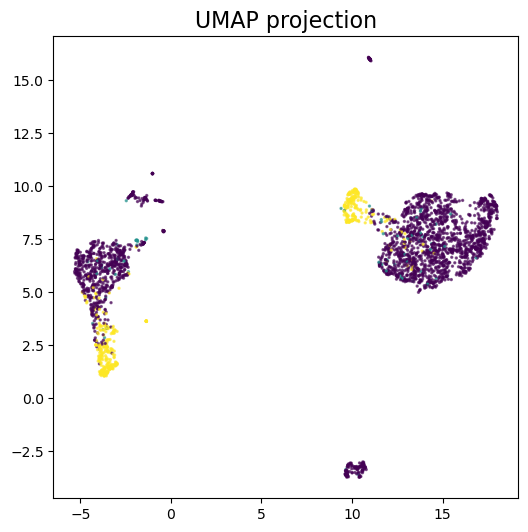

In [24]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6,6))
# plt.rcParams["figure.figsize"] = (7,7)
lab =[0, 1, 2]

scatter =ax.scatter(
    embedding[:, 0],
    embedding[:, 1],
    alpha=0.6,
    c=np.array(embed_df['label']),
    label=lab,
    s=2)
# ax.legend()
scatter
# plt.gca().set_aspect('equal', 'datalim')
# plt.title('UMAP projection', fontsize=16)
ax.set_title('UMAP projection', fontsize=16)
# plt.show()

In [25]:
embed_df['embed'].shape

(3000, 1024)

In [26]:
from sklearn.decomposition import PCA
pca = PCA(n_components=3)
pca.fit(embed_df['embed'])
pcaembed = pca.transform(embed_df['embed'])
pcaembed.shape

(3000, 3)

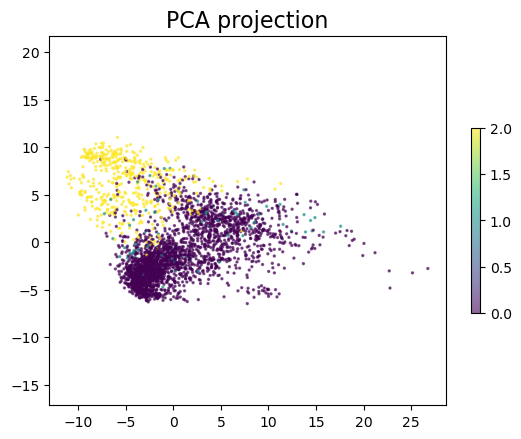

In [27]:
sc= plt.scatter(
    pcaembed[:, 0],
    pcaembed[:, 1],
    alpha=0.6,
    c=embed_df['label'],
s=2)
plt.gca().set_aspect('equal', 'datalim')
plt.title('PCA projection', fontsize=16)
plt.colorbar(sc, shrink=0.5, pad=0.05)
# plt.legend()

In [28]:
# fig = plt.figure()
# ax = fig.add_subplot(111, projection='3d')


# ax.scatter(embedding[:, 0], embedding[:, 1], embedding[:, 2], c=embed_df['label'], marker='o')

### Init Simple classifier

In [29]:
cls = Classifier(num_classes=2,
                 encoder=encoder,
                 num_training_samples=len(test_dataset),
                 batch_size=BATCH_SIZE,
                 max_epochs=None,
                 learning_rate=0.001, 
                 dropout=0.3).cuda()


## Test Classifier with Barlow Twins vector

In [30]:
# ckpt_dict = torch.load('checkpoints_tower_cls/epoch=4-step=8220.ckpt')  
# cls.load_state_dict(ckpt_dict['state_dict'])


In [31]:
model = cls.load_from_checkpoint(
    checkpoint_path='checkpoints_tower_cls/epoch=18-step=31236.ckpt',
    hparams_file="lightning_log/sversion_3/hparams.yaml",
    map_location='cuda',
    num_classes=2,
    encoder=encoder,
    num_training_samples=len(test_dataset),
    batch_size=BATCH_SIZE
)


FileNotFoundError: [Errno 2] No such file or directory: '/home/m.caros/work/3DSemanticSegmentation/src/bt/notebooks/checkpoints_tower_cls/epoch=18-step=31236.ckpt'

In [ ]:
len(test_dataset)

In [ ]:
torch.set_float32_matmul_precision('medium')

In [ ]:
# BATCH SIZE = 1
trainer = Trainer(
    accelerator="auto",
    devices=1 if torch.cuda.is_available() else None)

# test (pass in the model)
trainer.test(model, dataloaders=test_loader)

In [ ]:
# batch=123
for i in range(10, 201):
    if len(test_dataset) % i == 0:
        print(i)